The concept is to investigate whether the multivariate autoregressive model can be treated as a classical ML problem to add regularization.

1. Implement classical algorithm proposed by Kamiński with OLS
2. Implement algorithm with sklearn's MultiTaskLasso (drop for now)
3. Implement encoder doing the same thing

In [1]:
import config as c
import pandas as pd
import numpy as np
import seaborn as sns
import mne
import matplotlib.pyplot as plt
from lib import *

In [2]:
fpr = load_memmap()
single_exam = fpr[1220] #randomly pick a recording

In [ ]:
#sanity check
#single_exam.shape

Not setting metadata
150 matching events found
No baseline correction applied
0 projection items activated
Using matplotlib as 2D backend.


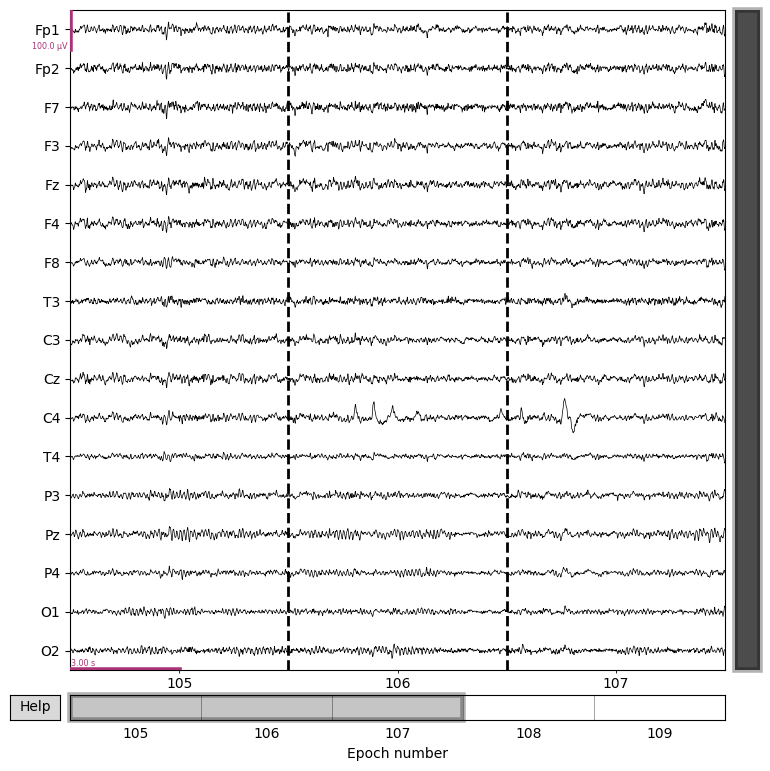

In [3]:
g = plot_epoch_eeg(single_exam, start_epoch = 105, end_epoch = 110, n_epochs_to_plot = 3)

In [4]:
one_window = single_exam[106, :, :]

Creating RawArray with float64 data, n_channels=17, n_times=768
    Range : 0 ... 767 =      0.000 ...     5.992 secs
Ready.


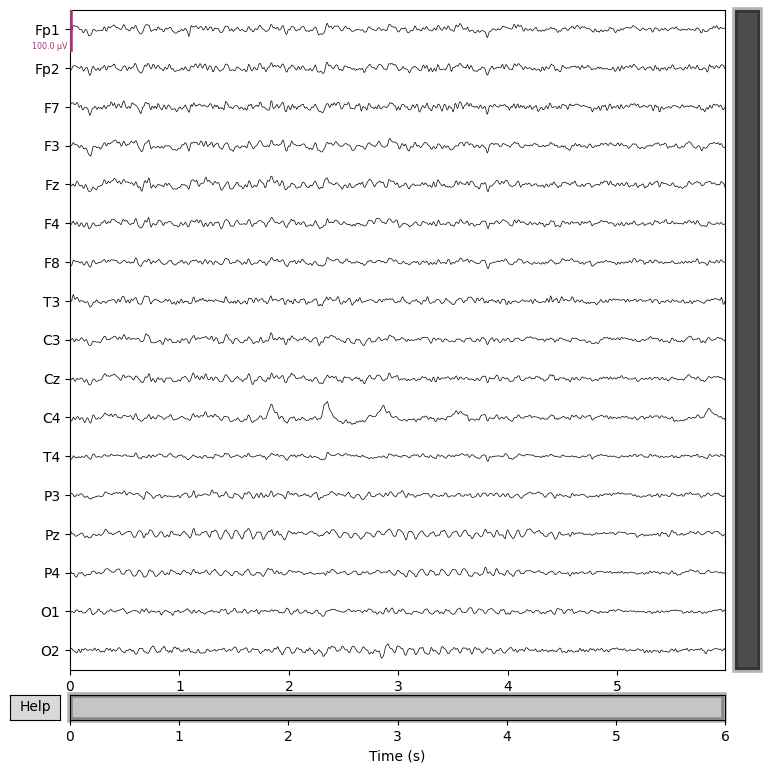

In [5]:
g = plot_one_window(one_window)

# traditional with sklearn

In [6]:
one_window_zscored = zscore_per_channel(one_window)
one_window_zscored

array([[ 9.2437968e-02, -9.9402899e-01, -1.1269472e+00, ...,
         5.2540827e-01,  3.7033170e-01,  3.8362205e-01],
       [-1.0673590e+00, -1.1799066e+00, -4.6967602e-01, ...,
         4.8632911e-01, -4.1804132e-01, -2.4759974e-01],
       [ 3.3936998e-01,  1.3137319e+00,  1.7785696e+00, ...,
        -8.9218509e-01, -3.1723681e-01,  2.0274317e-01],
       ...,
       [ 9.7705799e-01,  5.7881802e-01, -4.3526566e-01, ...,
         9.8484615e-04, -5.0548720e-01, -9.4119668e-01],
       [-6.4089584e-01, -5.2301598e-01, -5.6825750e-02, ...,
         1.0399733e+00,  4.9572921e-01,  6.9397017e-02],
       [ 2.7929869e-01,  1.0398926e+00,  1.1275957e+00, ...,
         9.6501464e-01,  3.3695710e-01, -4.6856377e-01]],
      shape=(17, 768), dtype=float32)

Creating RawArray with float64 data, n_channels=17, n_times=768
    Range : 0 ... 767 =      0.000 ...     5.992 secs
Ready.


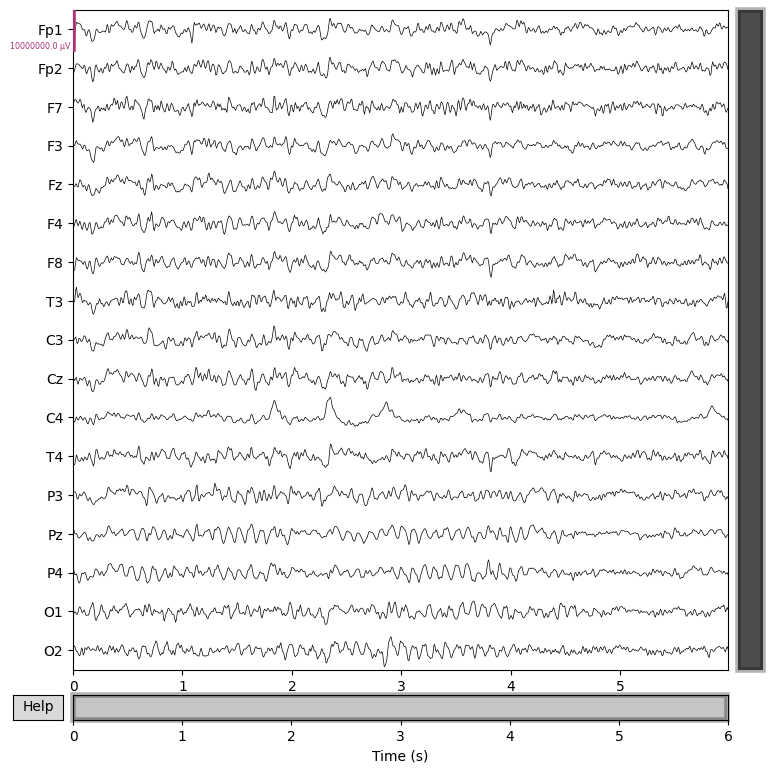

In [7]:
g = plot_one_window(one_window_zscored, scalings = dict(eeg=5))

Specialized econometric function designed to build the Block-Toeplitz matrices (also called diagonal-constant matrix) required to solve the Yule-Walker equations for Multivariate Autoregressive (MVAR) estimation. The function is doing the caltulations of autocovariance and cross-covariance matrices across multiple channels. For my application the trial approch is not plausible, thus deleted from initial implementation. (the goal is to certainly not average the matrices because there is no reoccuring experimental setting).

For my application it is save to set common order to 9 (we are aiming at around 5 frequency peaks) (this is shown in another notebook by sampling the dataset to probe for PSDs and AIC criterion). Considering the set length of the epoch to 6 x 128 the unbiased version of the algorithm can be safely used (iwhat = 2).

The np.linalg.solve(cov_matrices) solves equation rleft * eeg = rright for the unknow regression coefficients. It solves the Yule-Walker linear system, being a direct formulation of Ordinary Least Squares.

## input: one epoch

### standard approach

In [8]:
AR_orig, _ = AR_coeff(one_window_zscored)

In [9]:
mvar_H_orig = mvar_H(AR_orig)

### sklearn regularized approach

In [10]:
AR_sklearn, _ = AR_coeff_lasso(one_window_zscored)

In [11]:
mvar_H_sklearn = mvar_H(AR_sklearn)

### prepare band-averaged features of non-normalized DTF (magnitude) & frequency normalized DTF

In [12]:
NDTF_orig = np.abs(mvar_H_orig) ** 2 #not normalized
ffDTF_orig = ffDTF(mvar_H_orig)

In [13]:
NDTF_sklearn = np.abs(mvar_H_sklearn) ** 2 #not normalized
ffDTF_sklearn = ffDTF(mvar_H_sklearn)

## visualization for one directed information flow

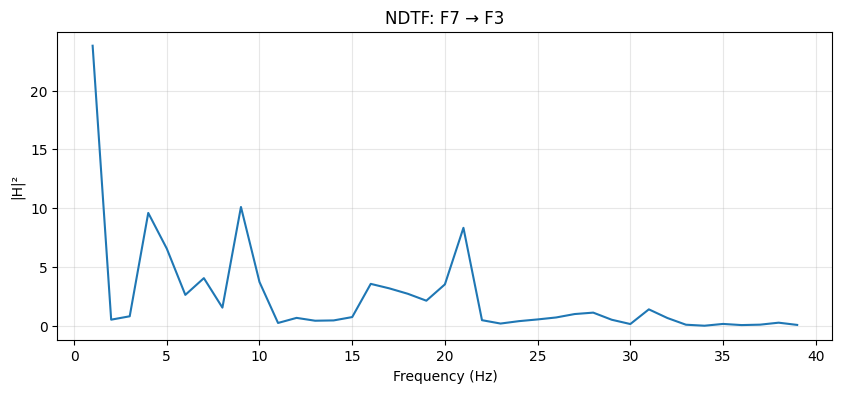

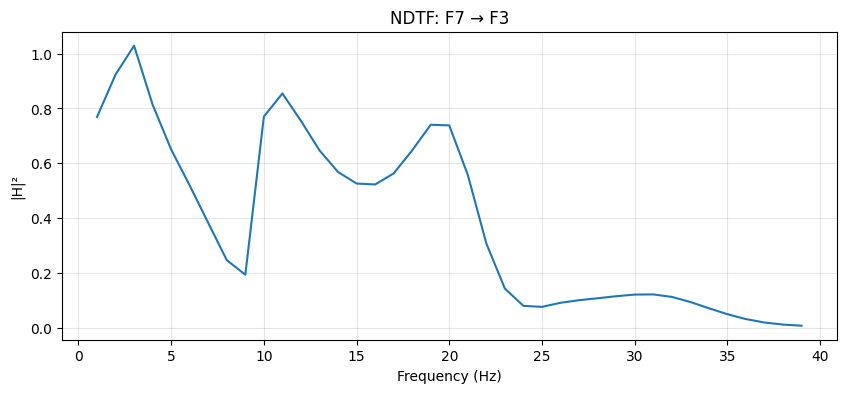

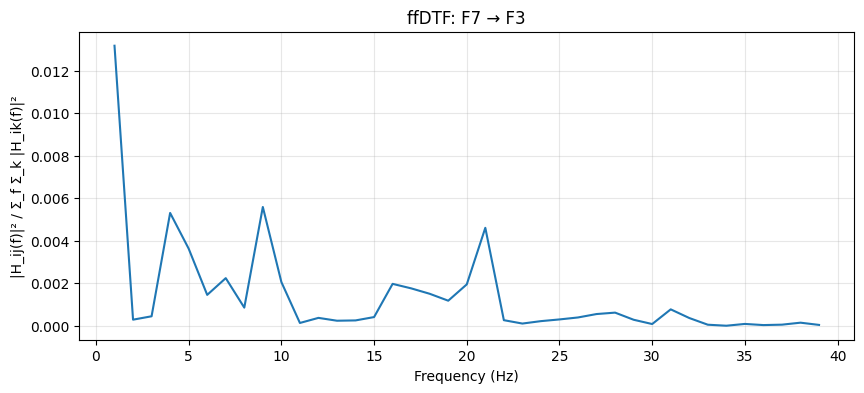

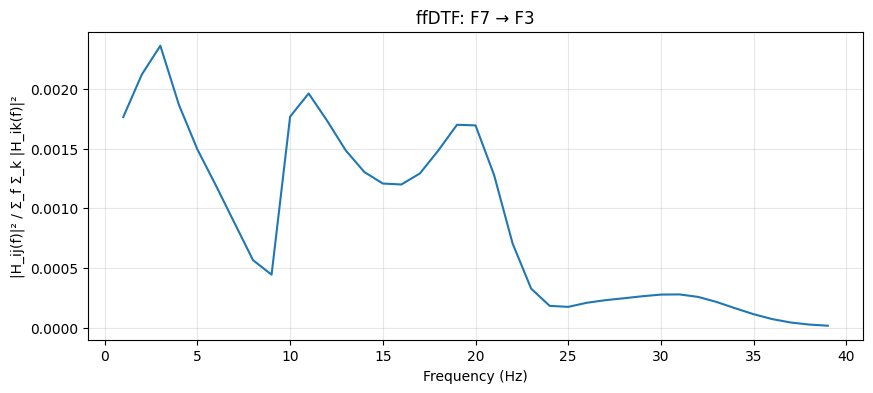

In [14]:
plot_one_flow(NDTF_orig, 2, 3, ylabel = "|H|²", conn_name = 'NDTF')
plot_one_flow(NDTF_sklearn, 2, 3, ylabel = "|H|²", conn_name = 'NDTF')
plot_one_flow(ffDTF_orig, 2, 3)
plot_one_flow(ffDTF_sklearn, 2, 3)

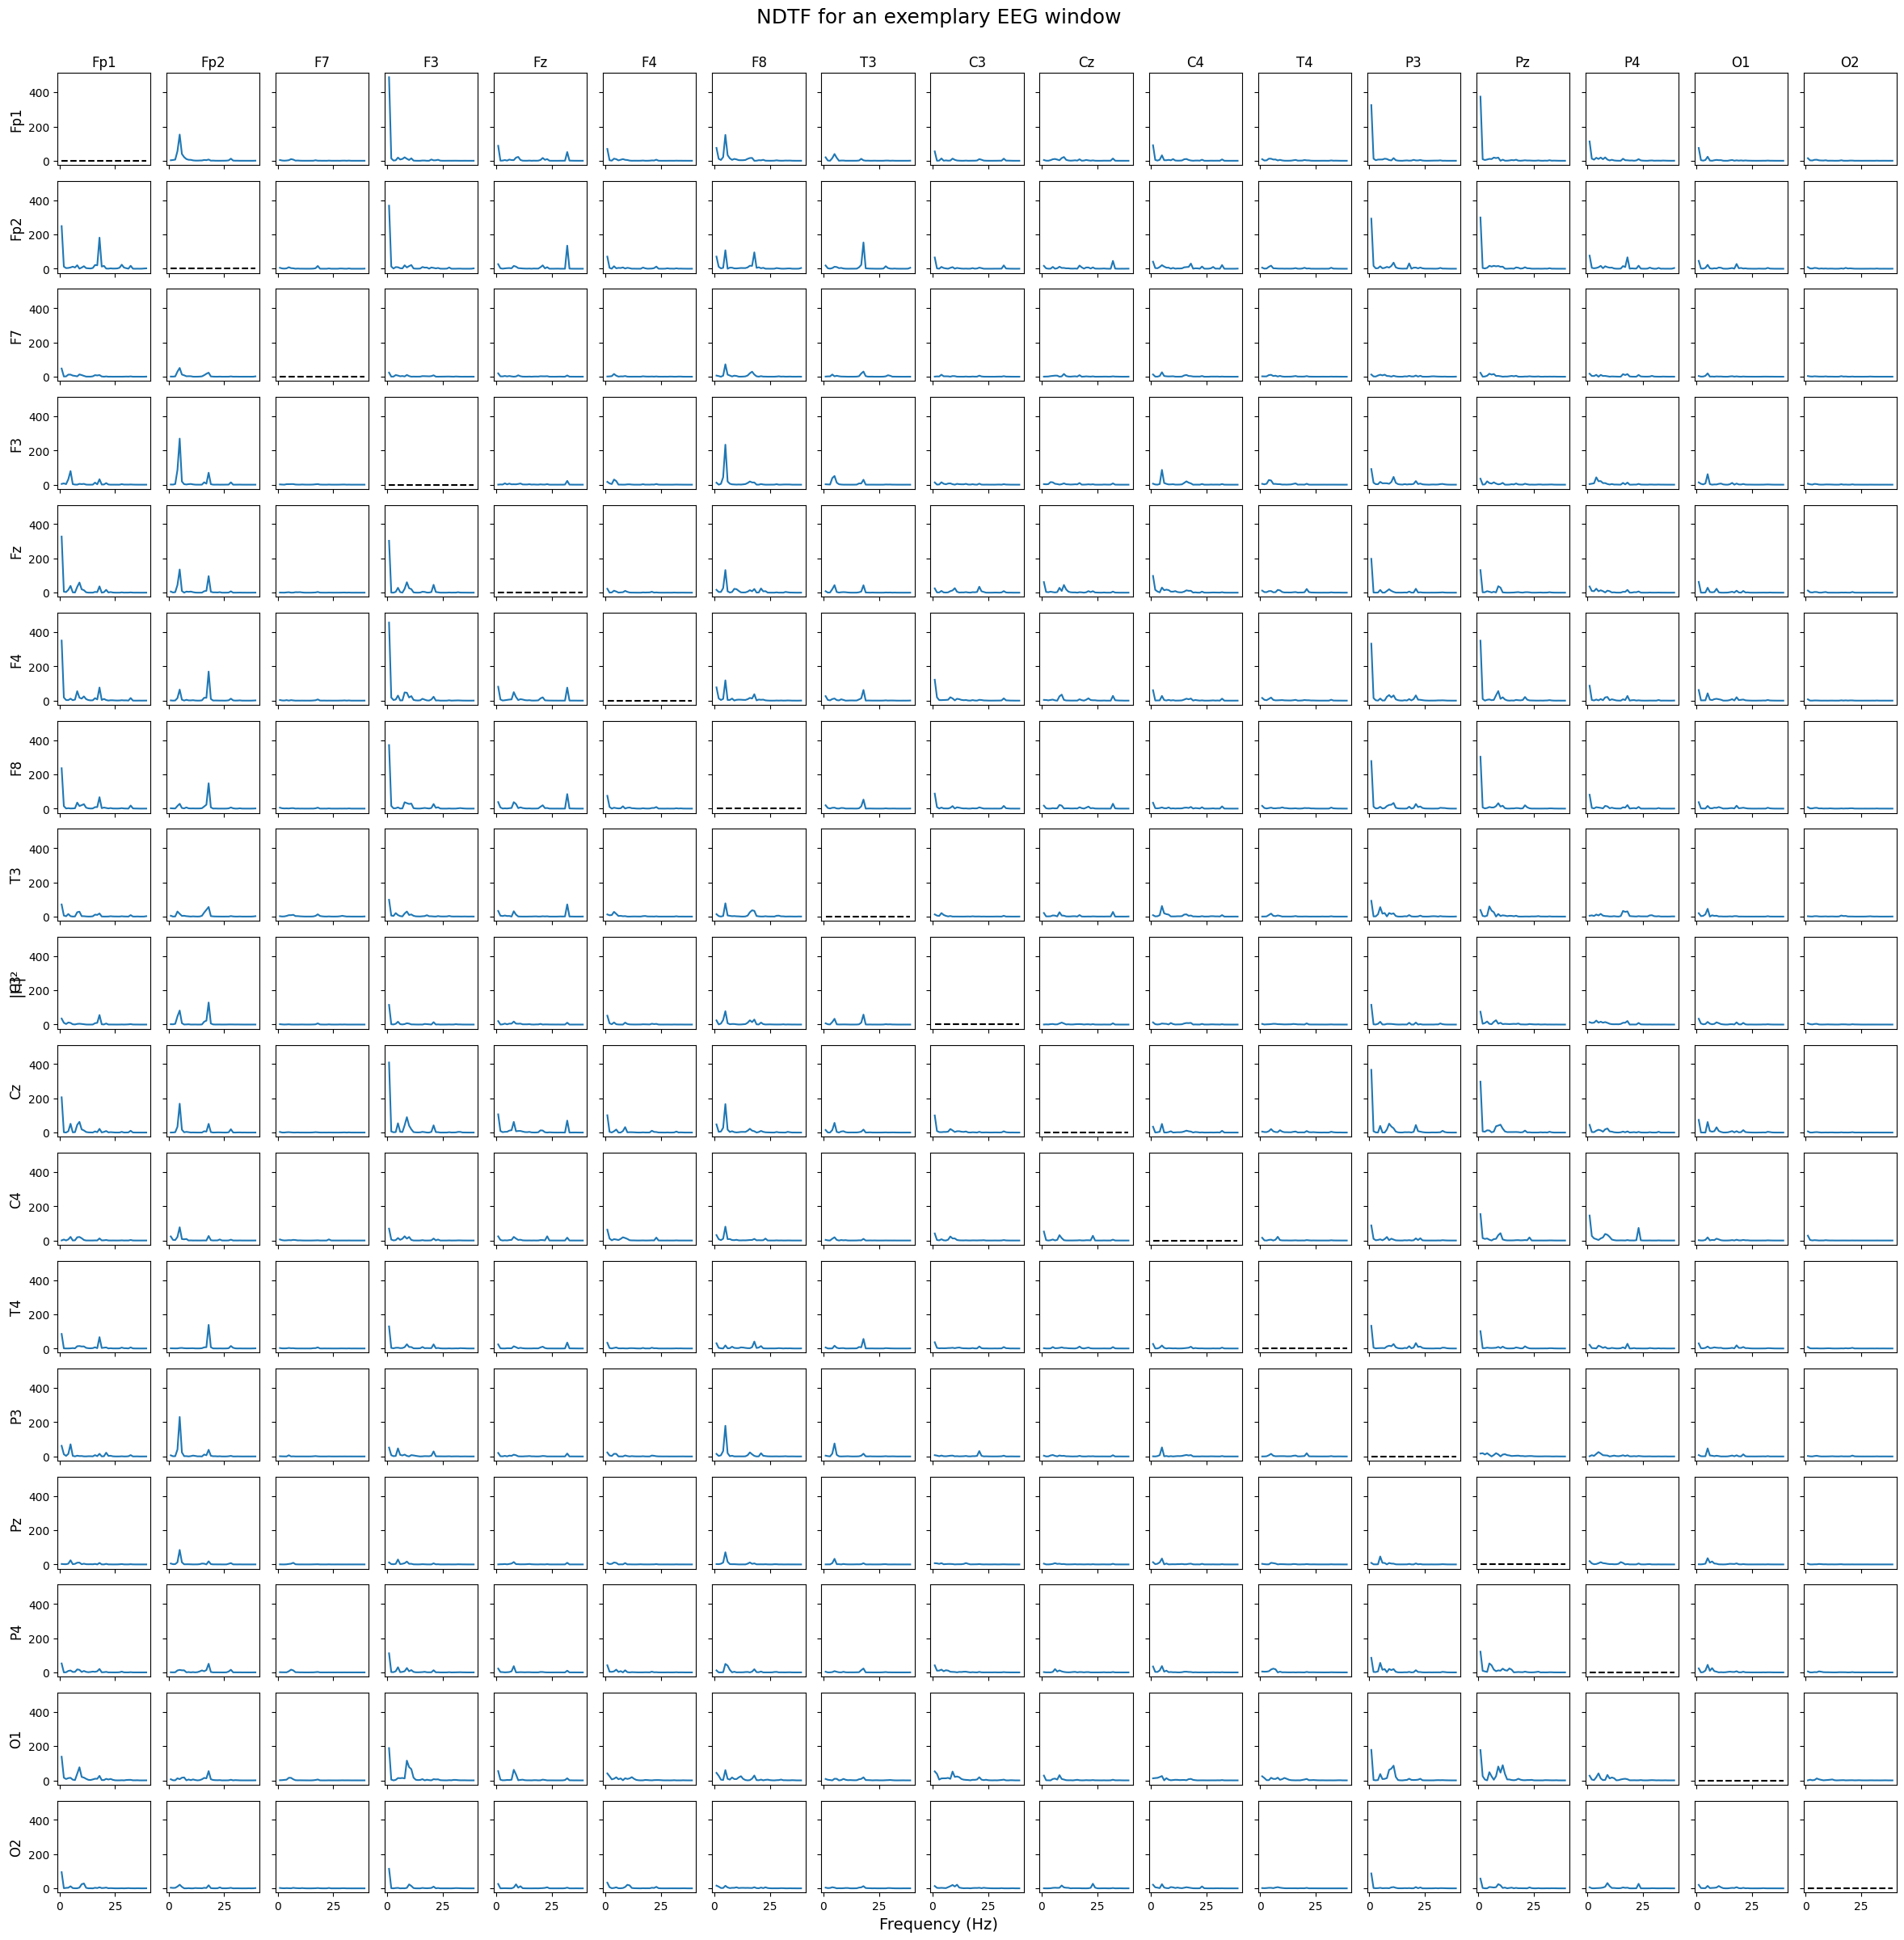

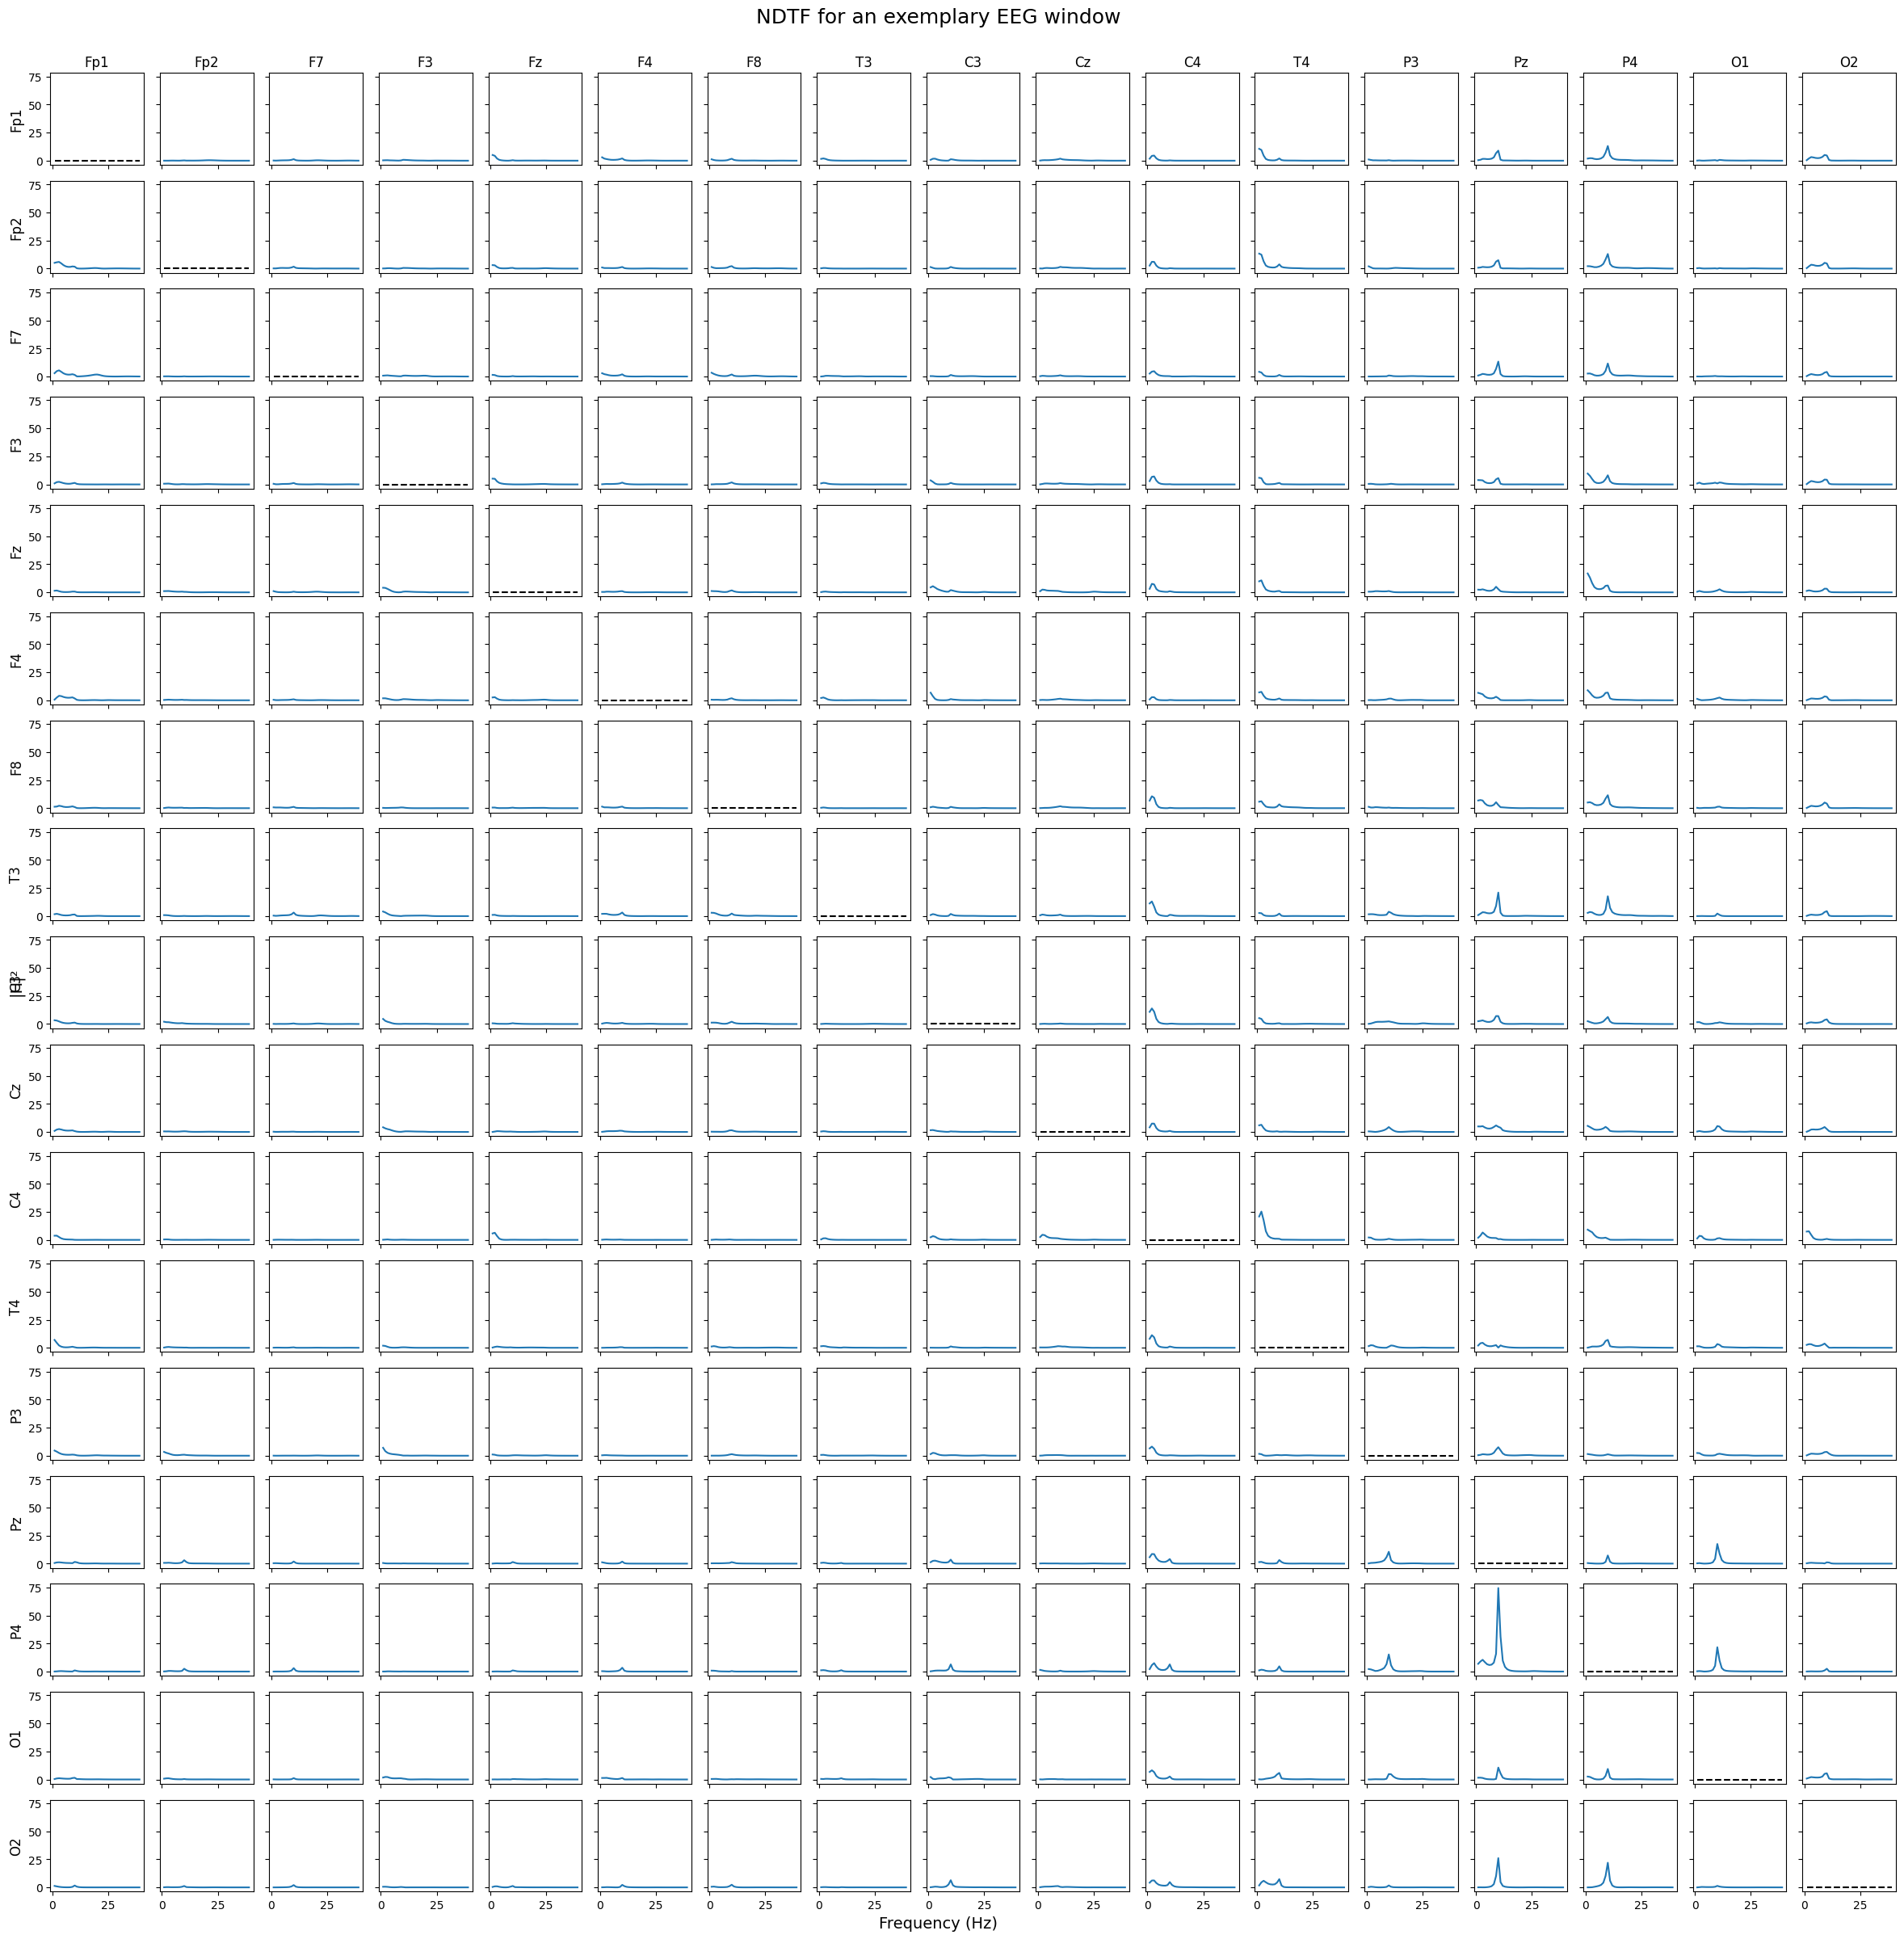

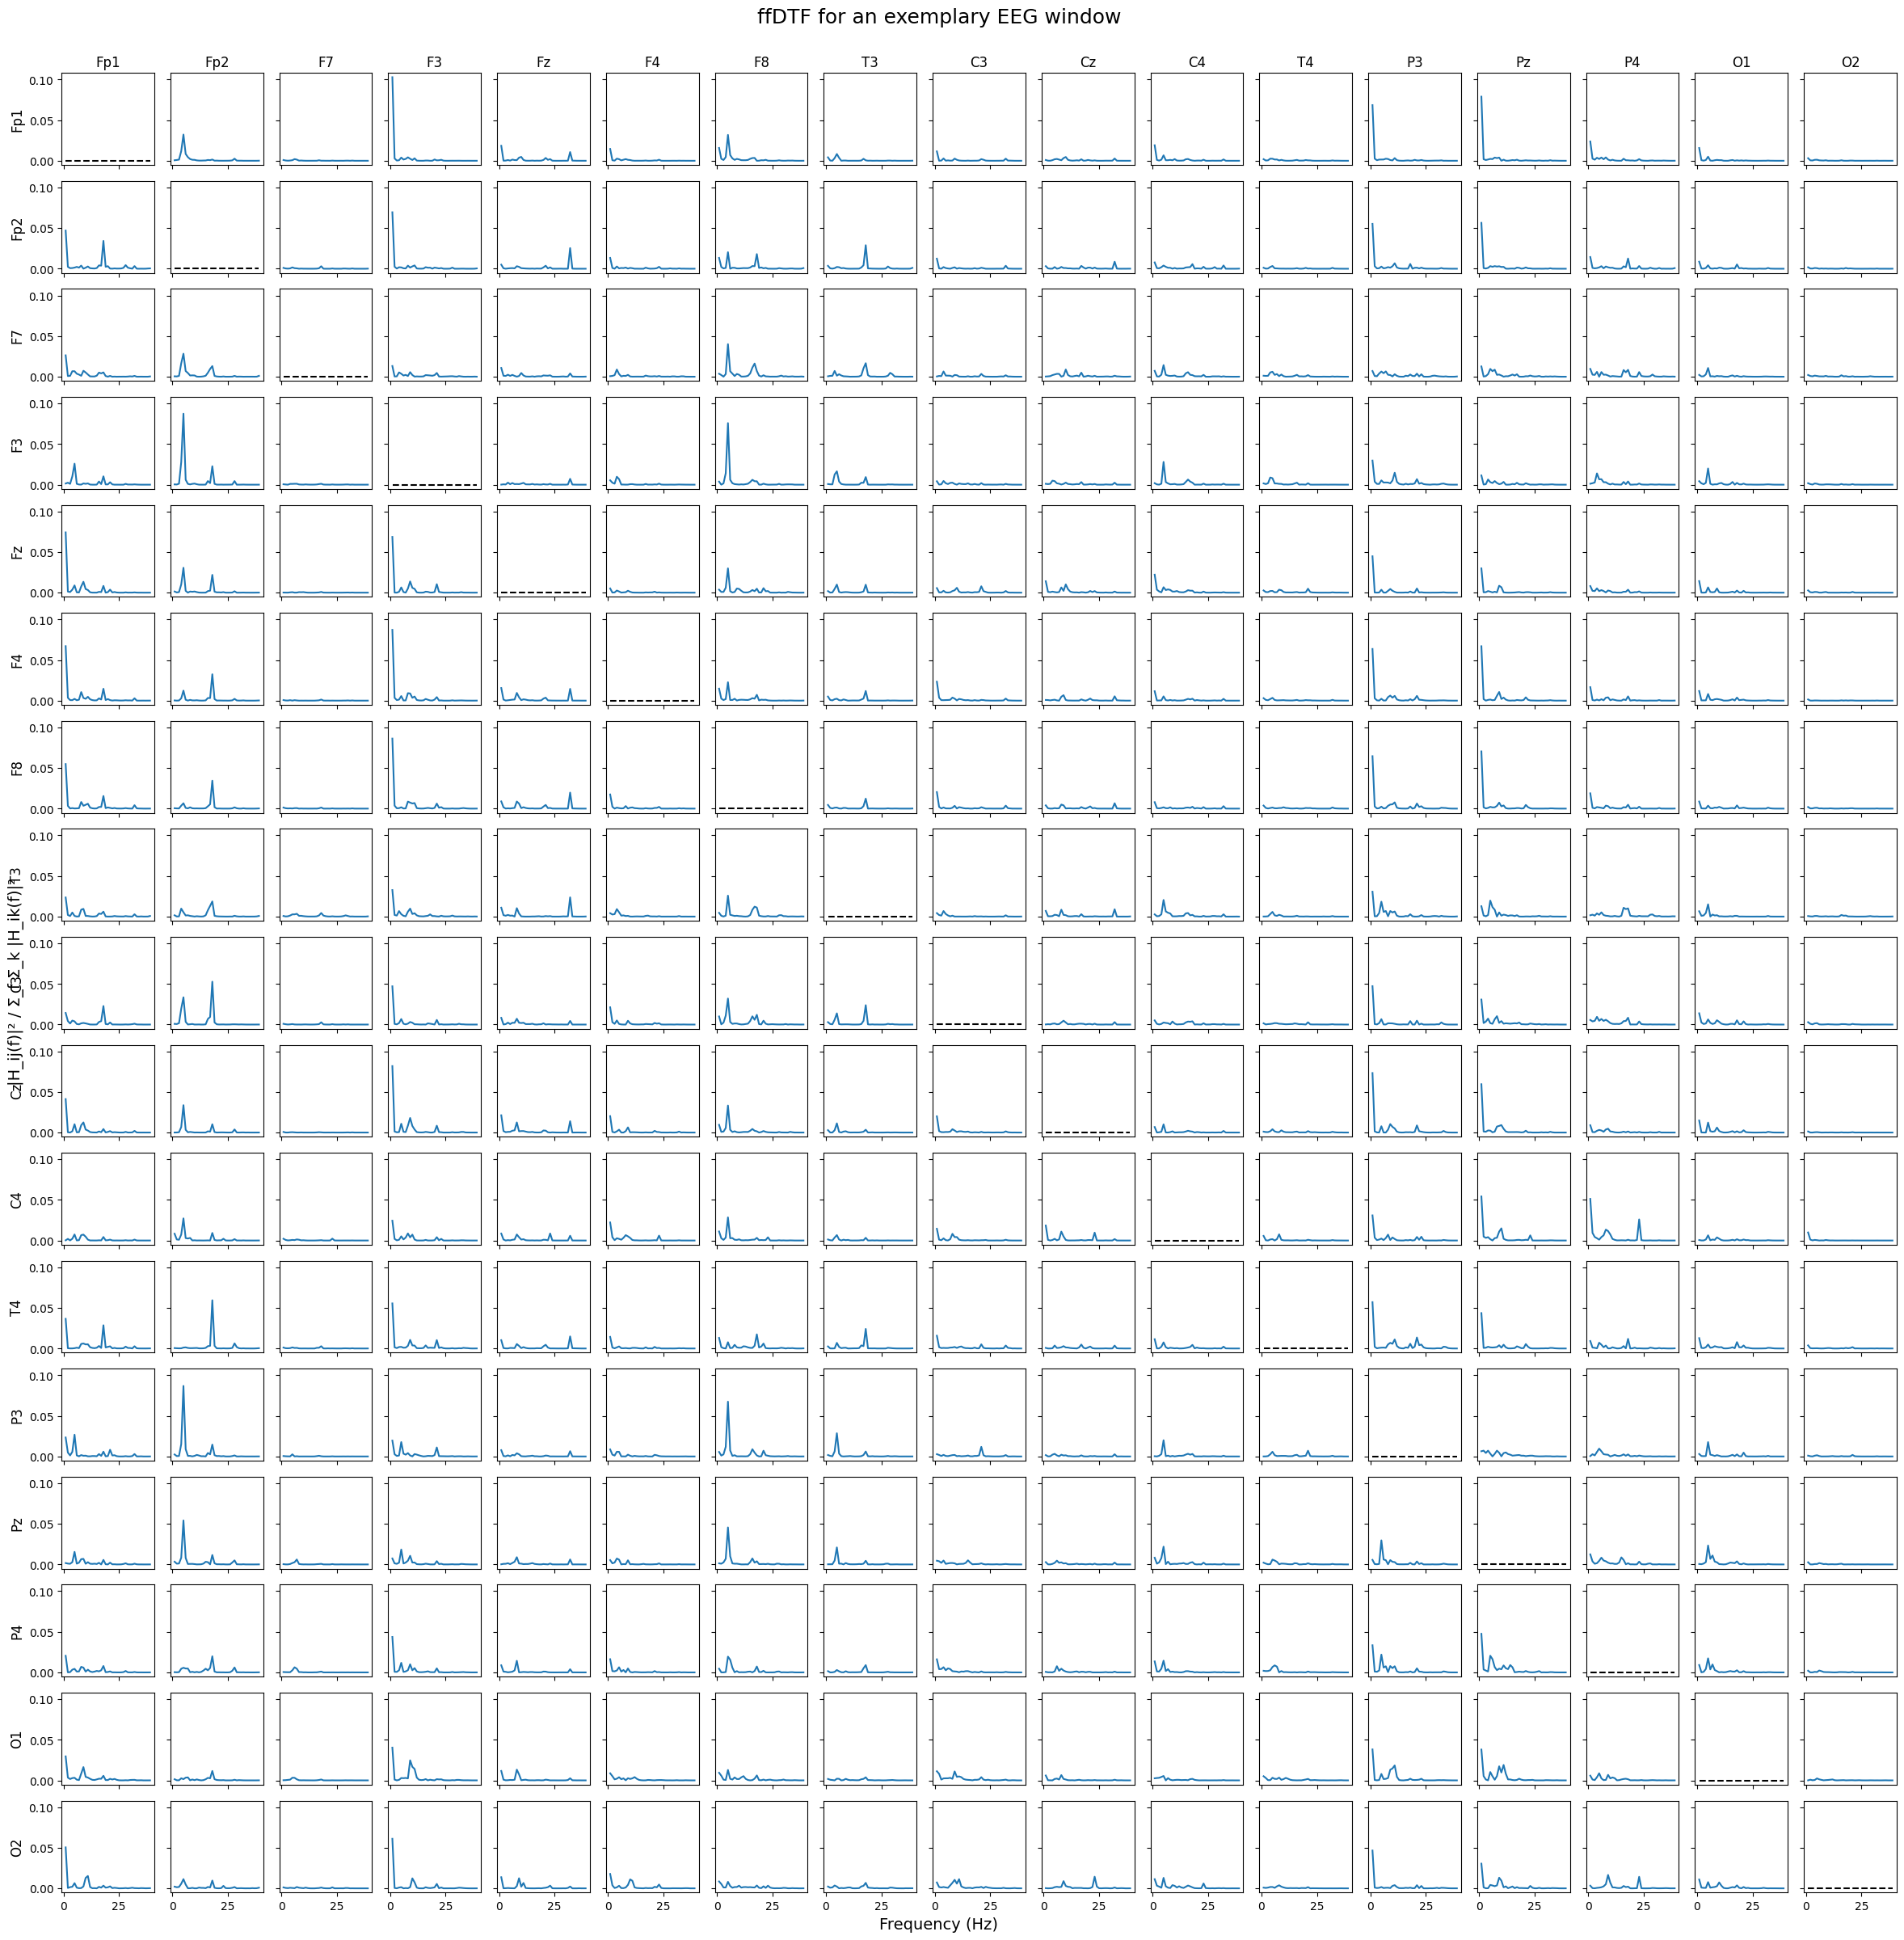

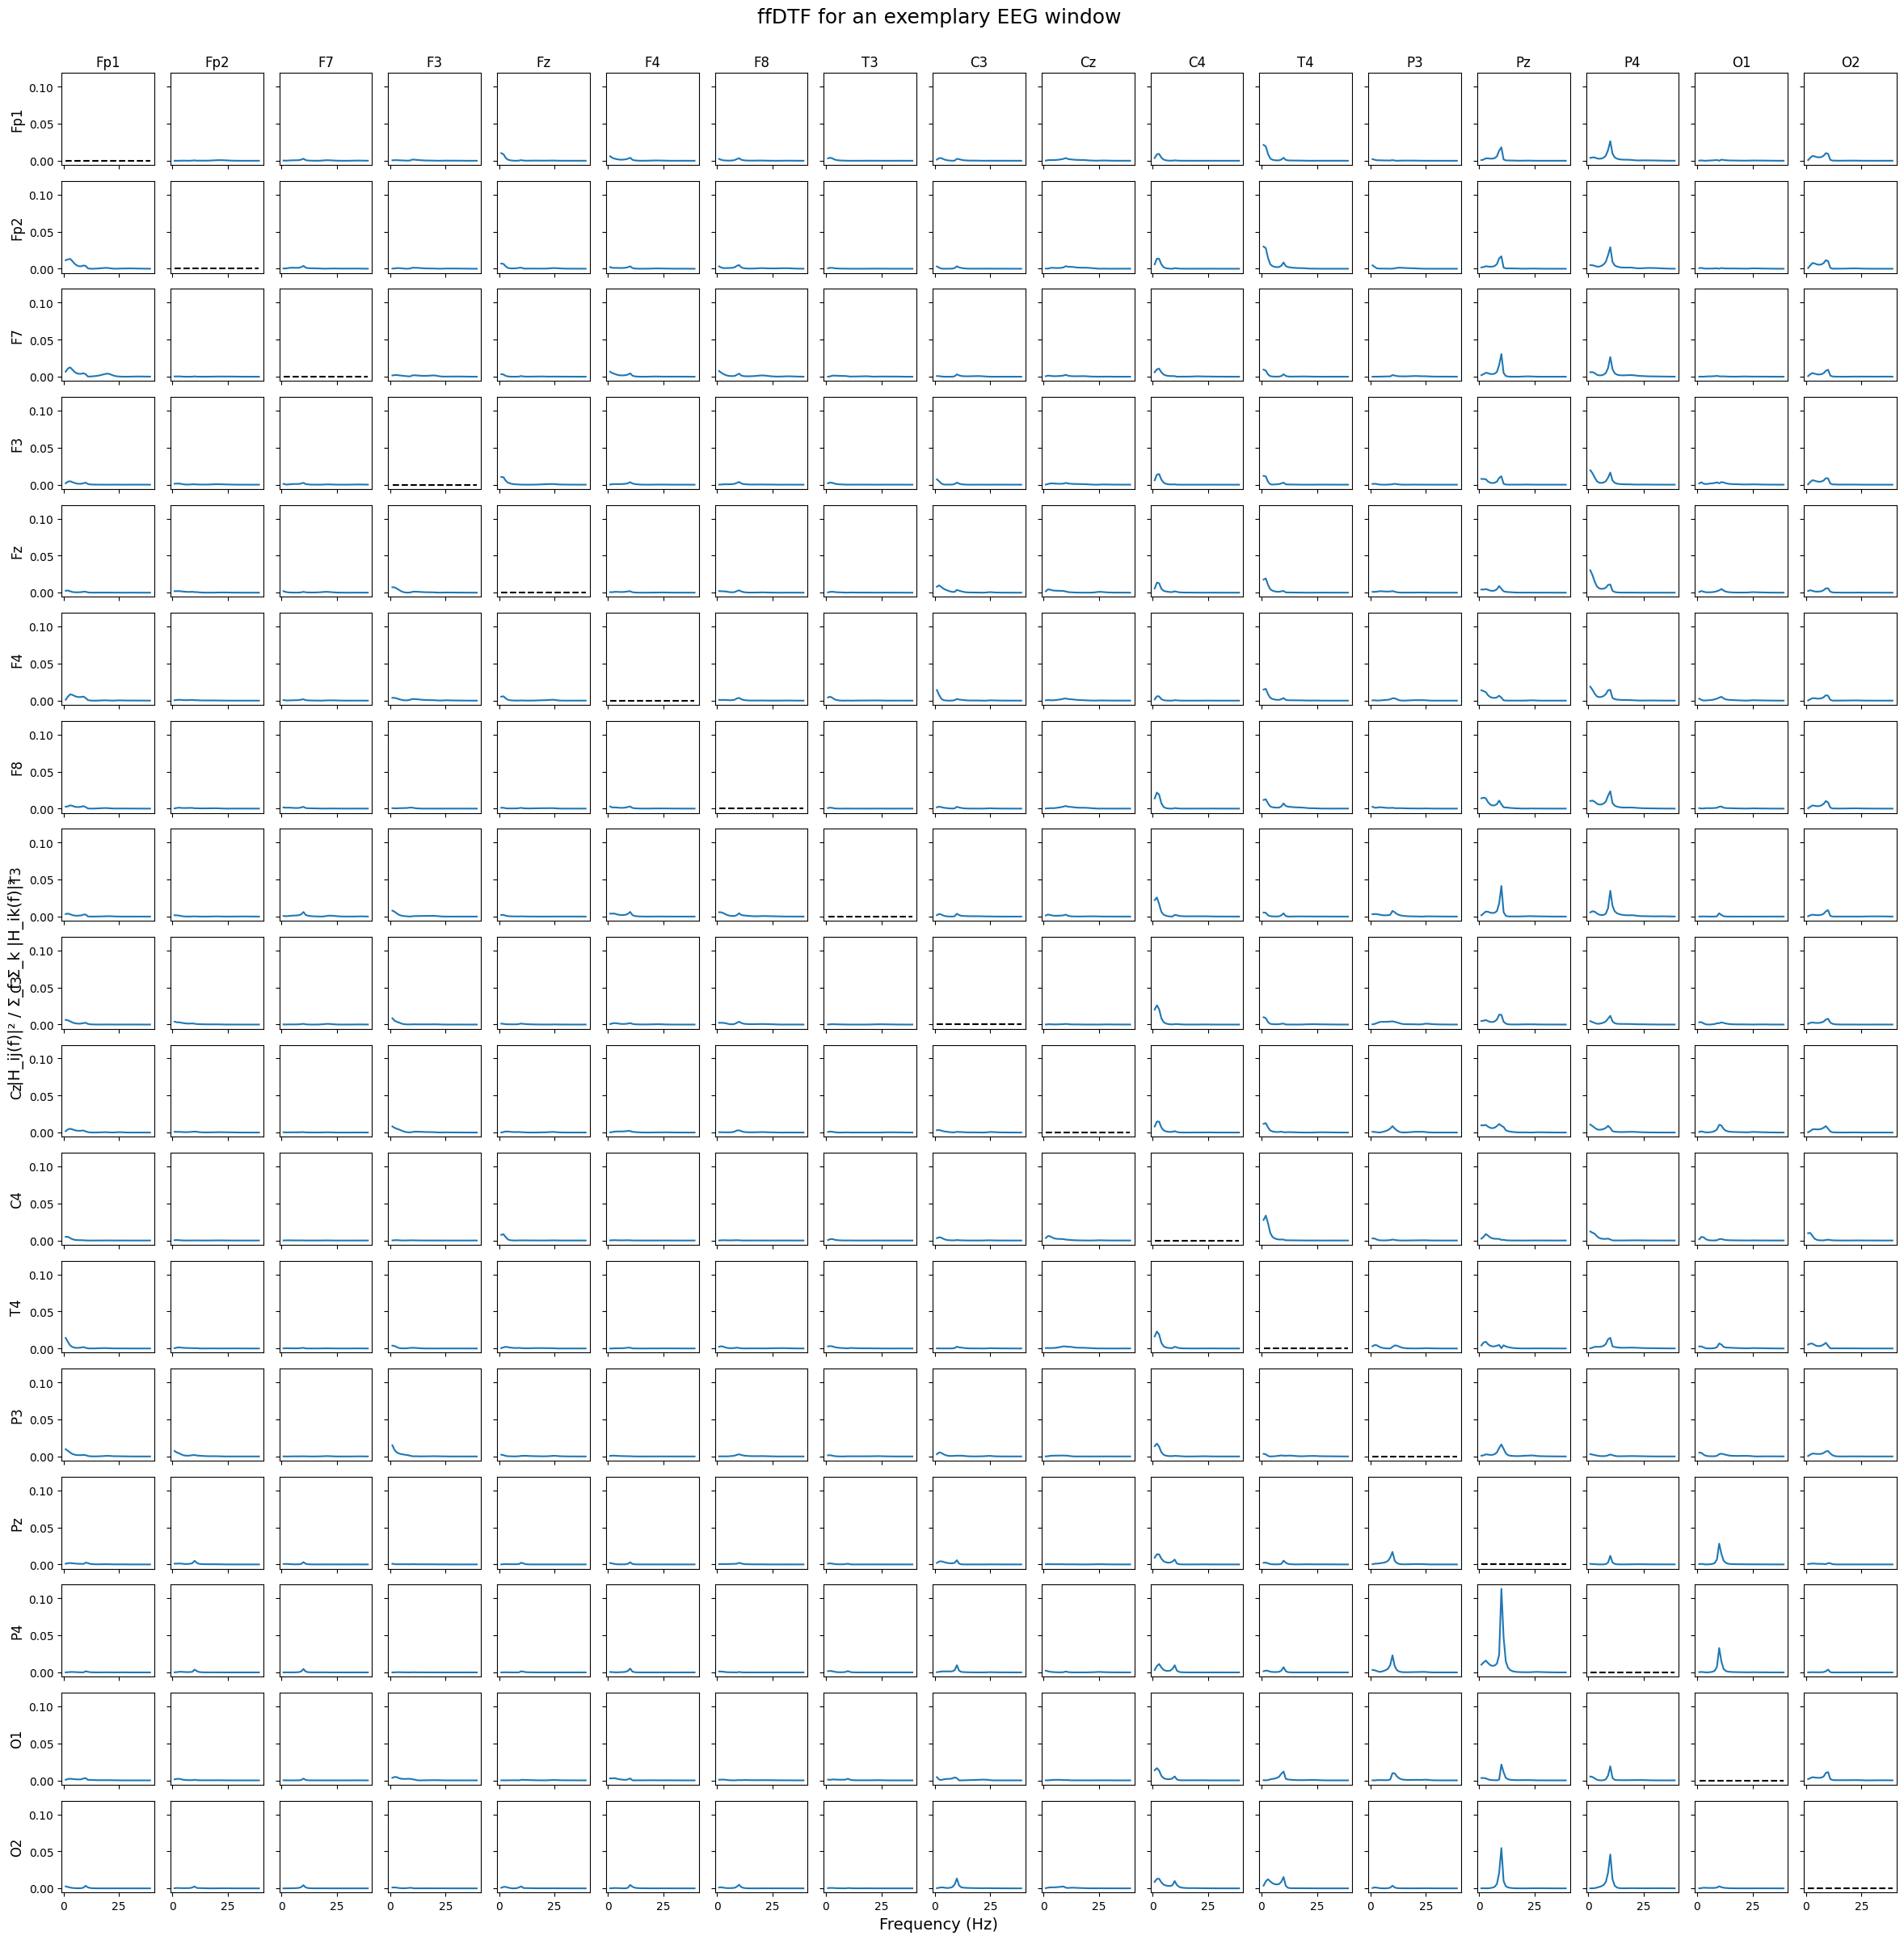

In [15]:
plot_all_flows(NDTF_orig, ylabel = "|H|²", conn_name = 'NDTF')
plot_all_flows(NDTF_sklearn, ylabel = "|H|²", conn_name = 'NDTF')
plot_all_flows(ffDTF_orig)
plot_all_flows(ffDTF_sklearn)

## create connectivity matrices aggregated over frequency bands

In [16]:
NDTF_orig_bands = aggregate_bands(NDTF_orig)
ffDTF_orig_bands = aggregate_bands(ffDTF_orig)

In [17]:
NDTF_sklearn_bands = aggregate_bands(NDTF_sklearn)
ffDTF_sklearn_bands = aggregate_bands(ffDTF_sklearn)

## visualize connectivity by bands

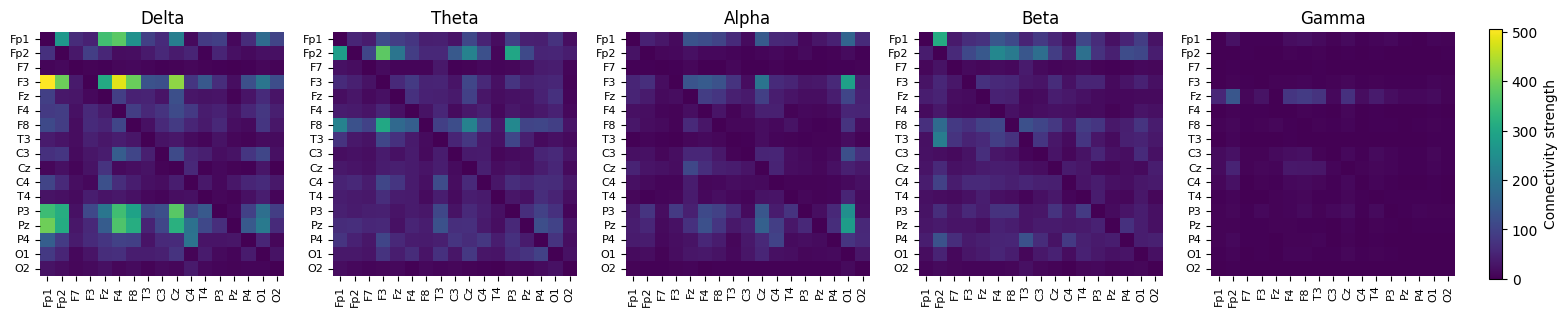

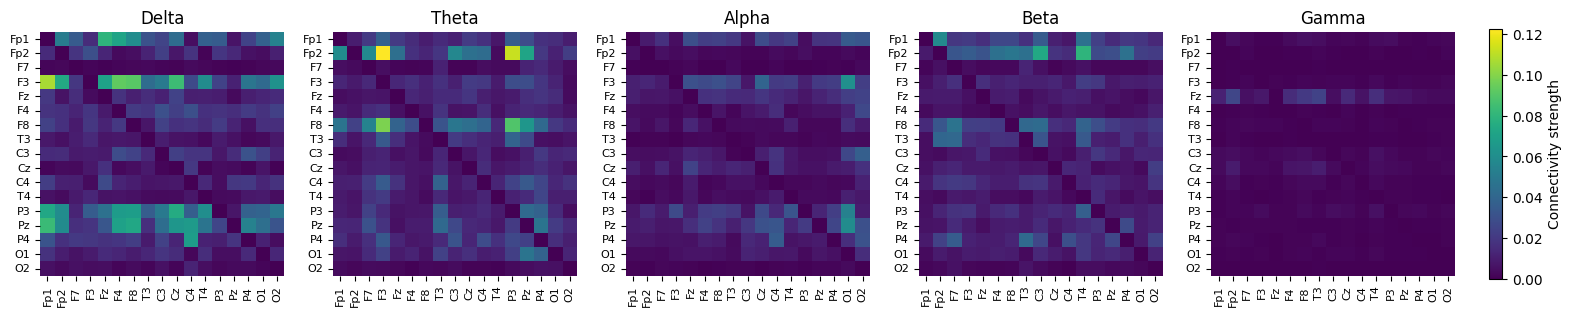

In [18]:
heatmap_bands(NDTF_orig_bands)
heatmap_bands(ffDTF_orig_bands)
plt.show()

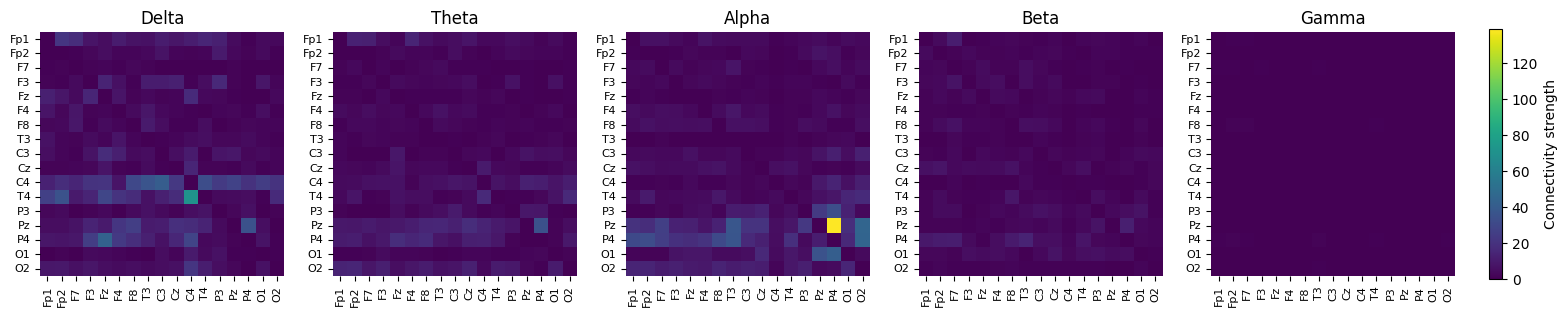

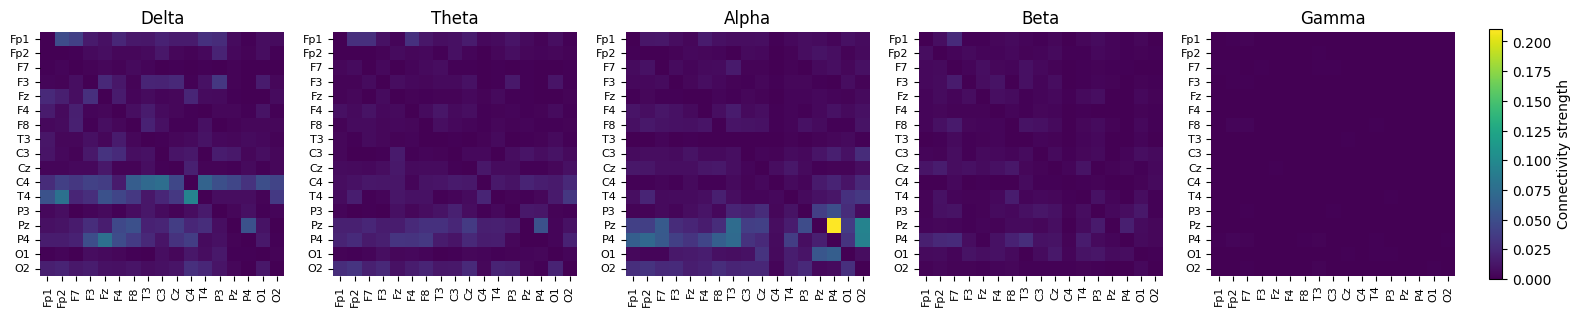

In [19]:
heatmap_bands(NDTF_sklearn_bands)
heatmap_bands(ffDTF_sklearn_bands)
plt.show()

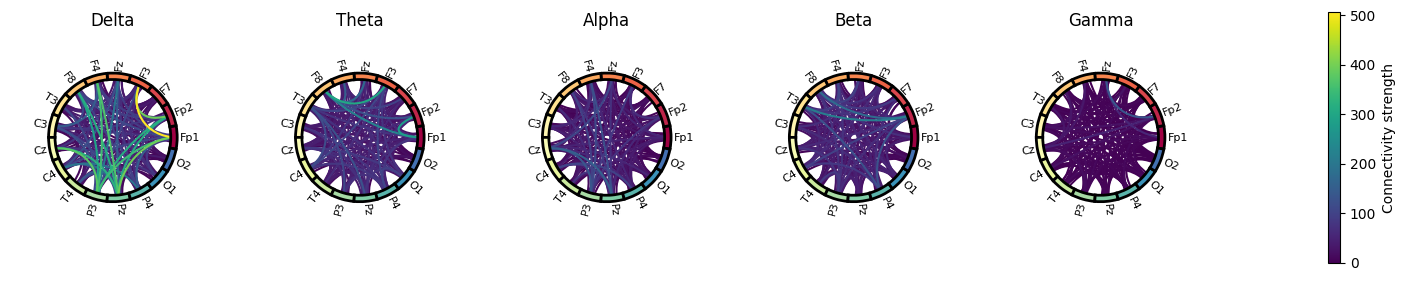

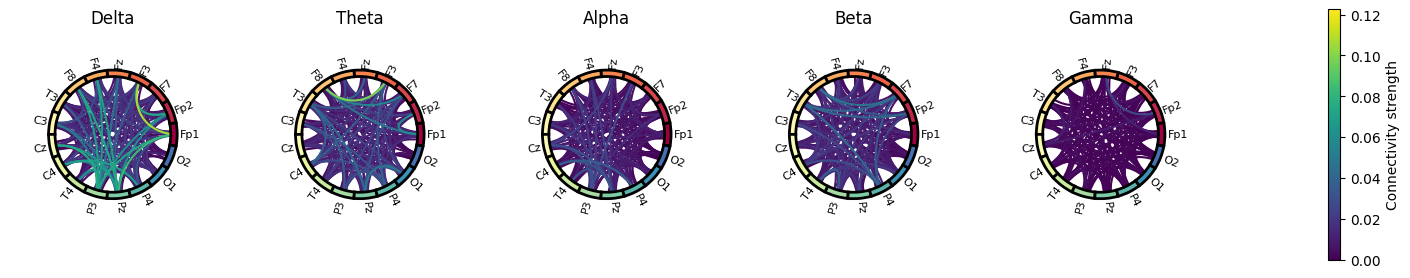

In [20]:
circle_bands(NDTF_orig_bands)
circle_bands(ffDTF_orig_bands)
plt.show()

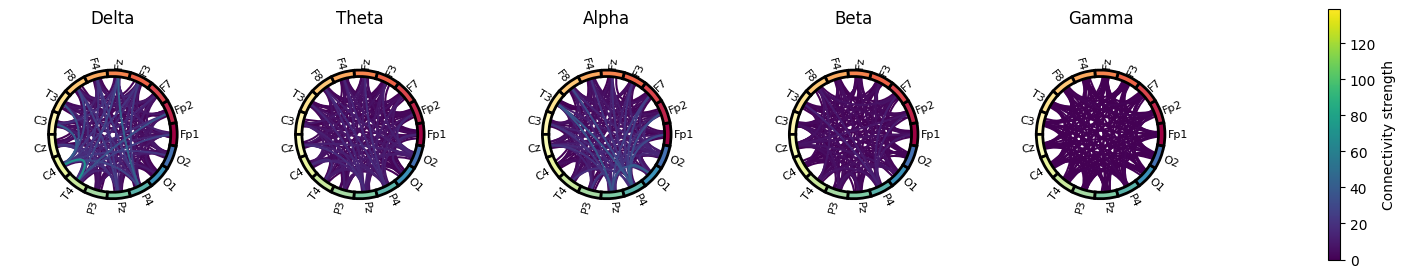

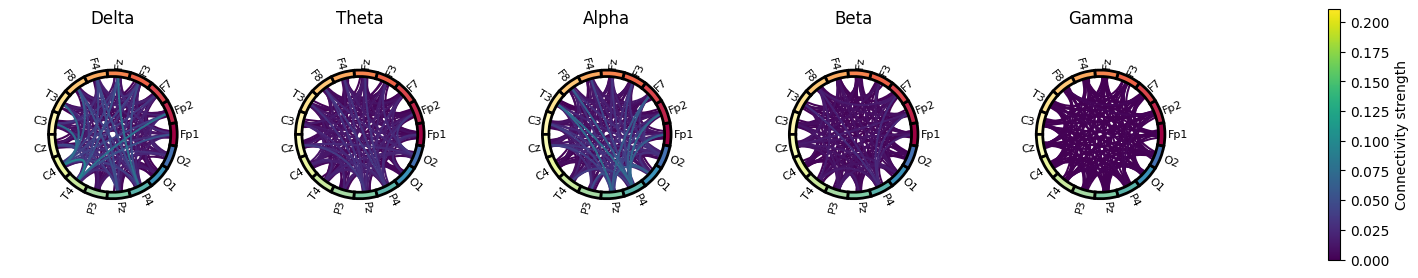

In [21]:
circle_bands(NDTF_sklearn_bands)
circle_bands(ffDTF_sklearn_bands)
plt.show()

## bands & graphs (visualize & create)

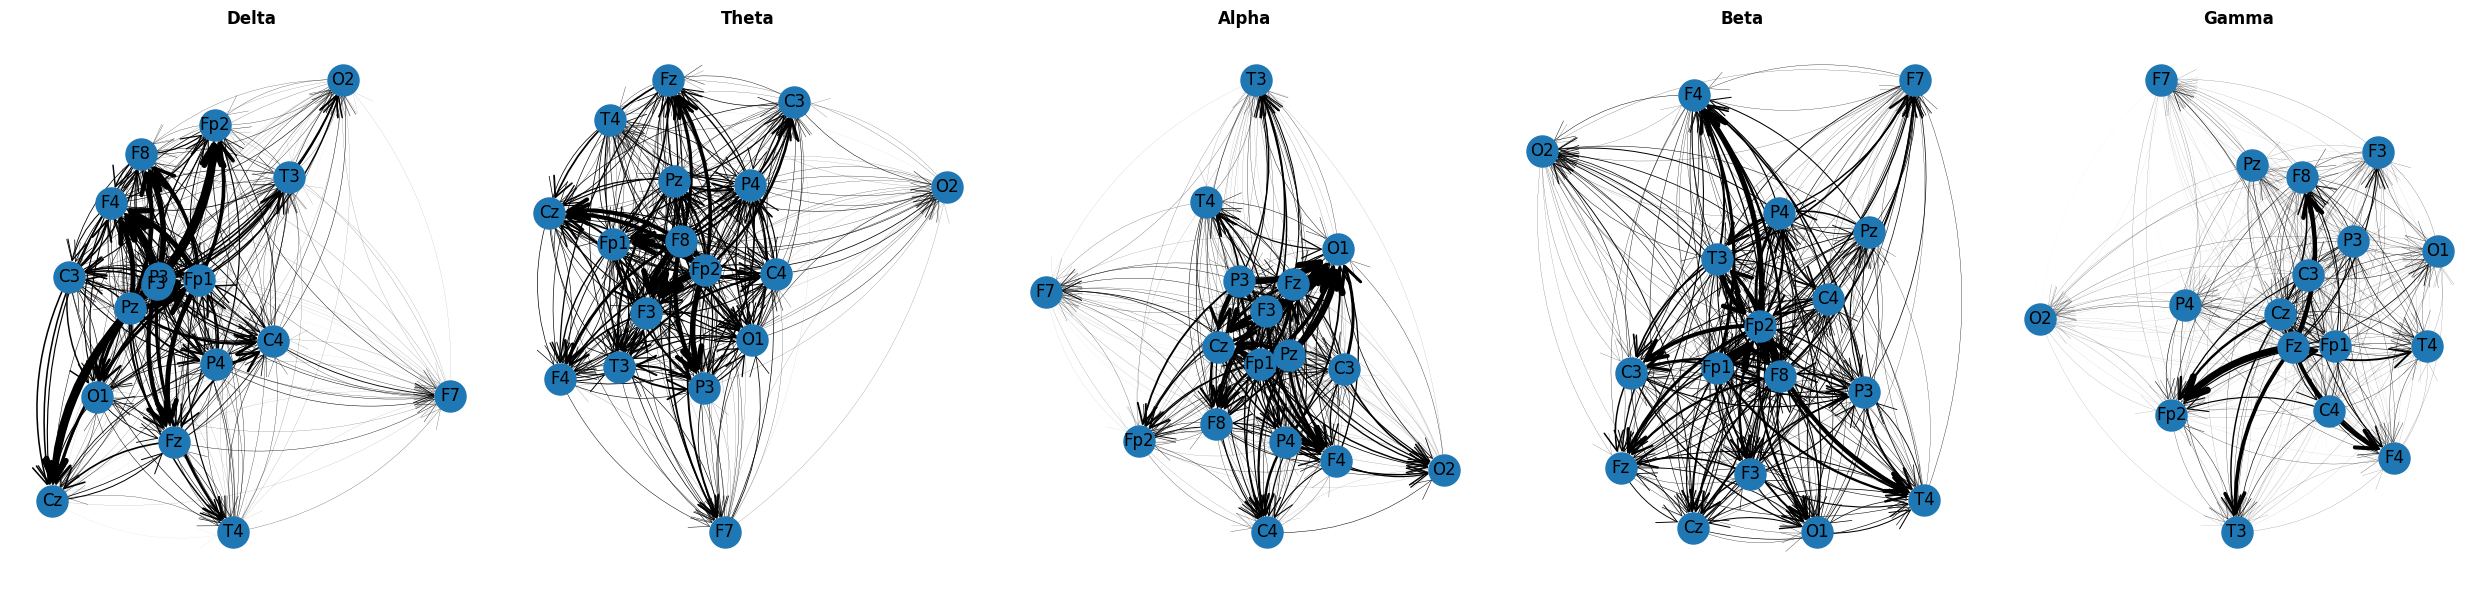

In [22]:
Gs_NDTF_orig = graph_bands(NDTF_orig_bands)
plt.show()

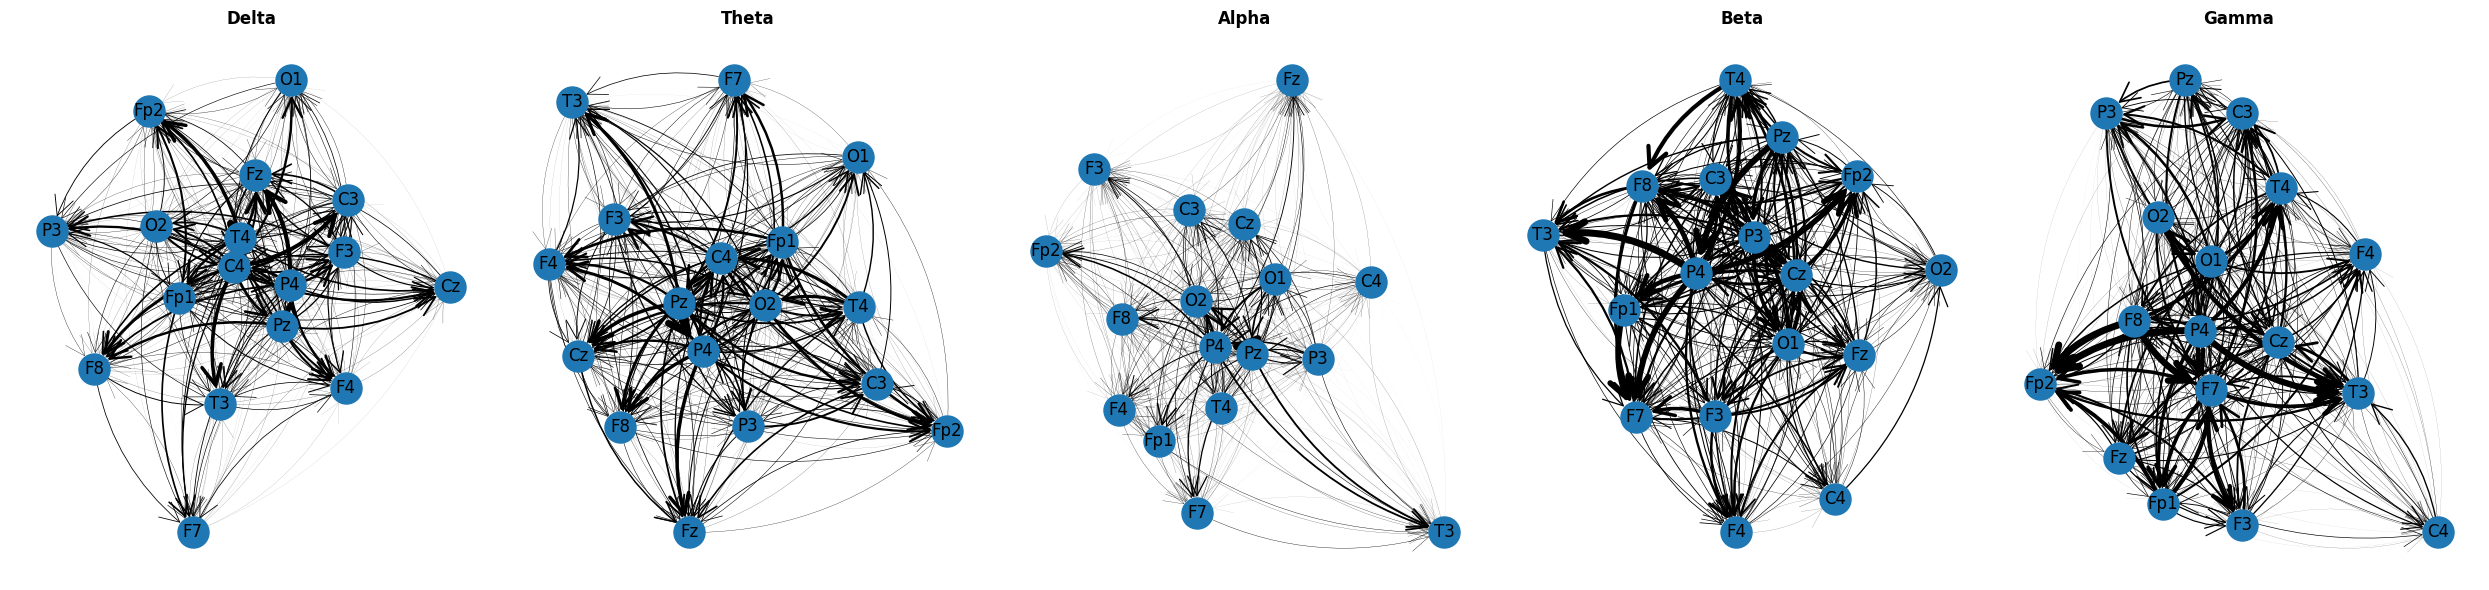

In [23]:
Gs_NDTF_sklearn = graph_bands(NDTF_sklearn_bands)
plt.show()

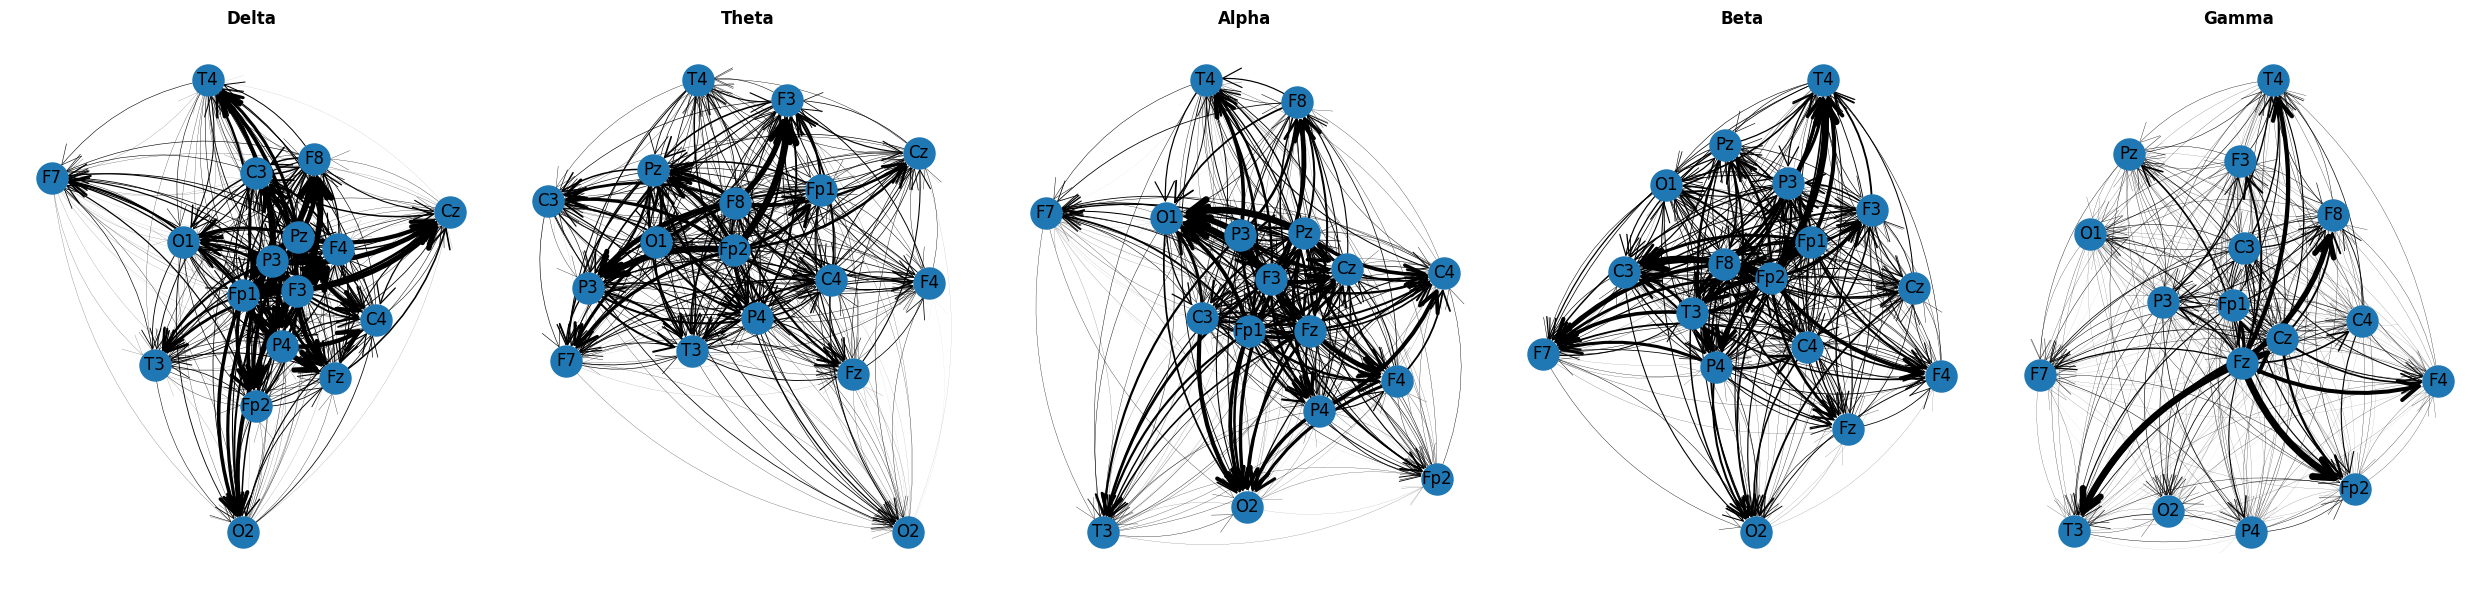

In [24]:
Gs_ffDTF_orig = graph_bands(ffDTF_orig_bands)
plt.show()

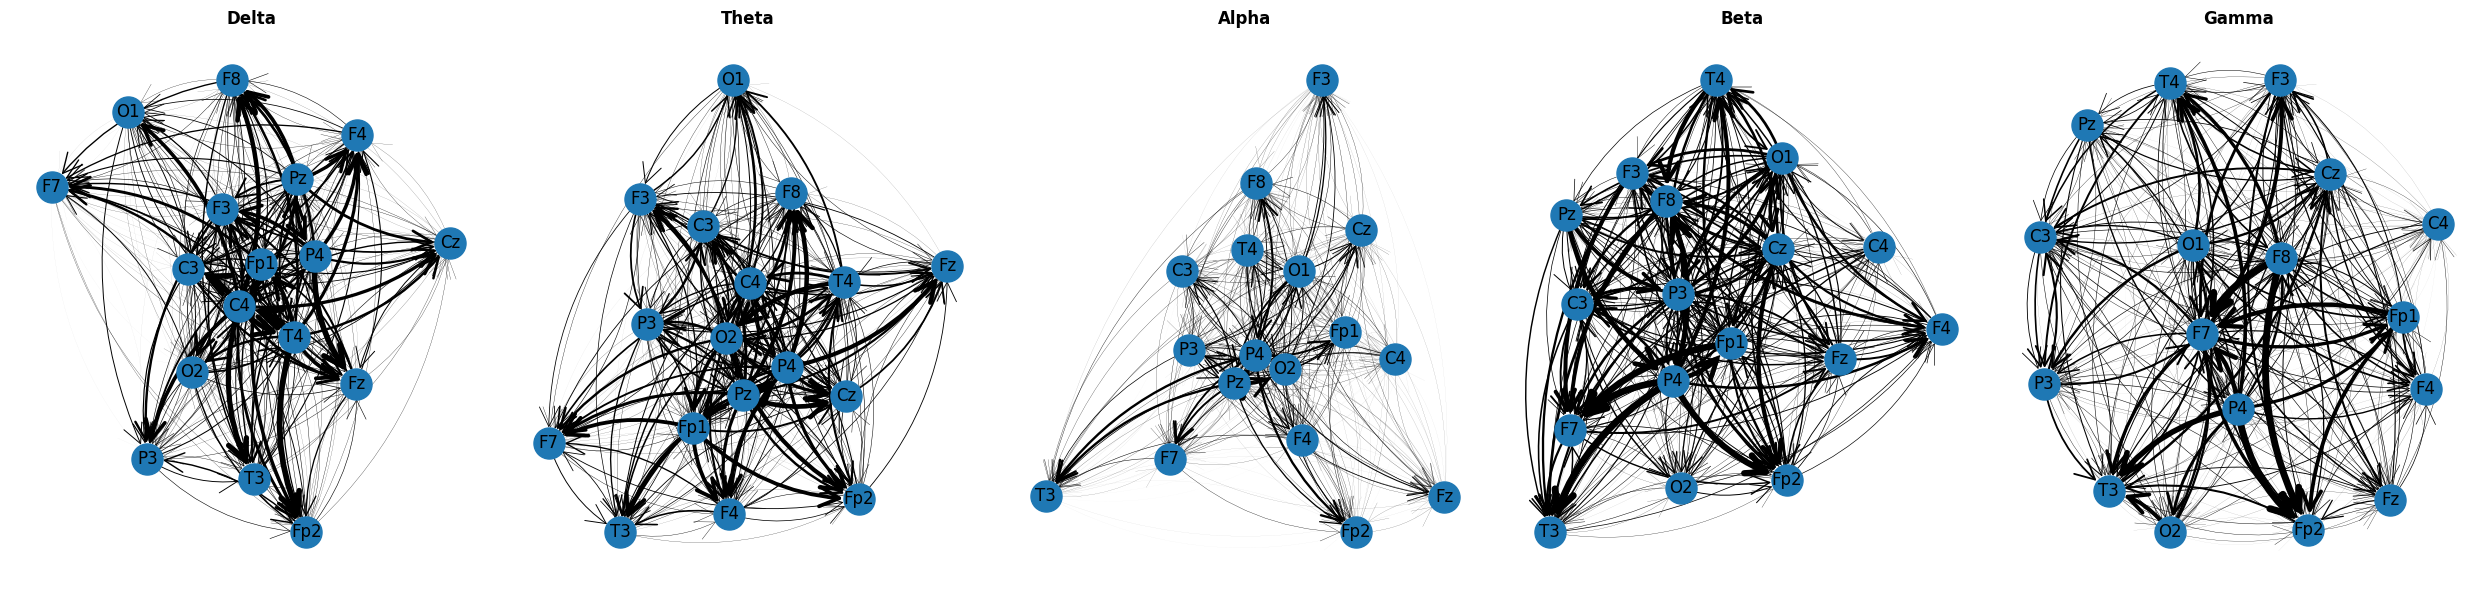

In [25]:
Gs_ffDTF_sklearn = graph_bands(ffDTF_sklearn_bands)
plt.show()

In [27]:
G_NDTF_orig_alpha = Gs_NDTF_orig['Alpha']
G_NDTF_orig_alpha